<h1 style="font-size: 42px;">Abnormal Flight Investigation</h1>

## Goal:

Find what distinguishes abnormal flights that the LSTM Autoencoder detected from those it missed across the 10 data splits.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from scipy import stats
import warnings
warnings.filterwarnings("ignore")


#PATHS
BASE_DIR     = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
DATA_VERSION = "v3_voltage_random10_interpolated"
SCORED_DIR   = BASE_DIR / "model_outputs" / f"lstm_autoencoder_{DATA_VERSION}_old_complex_logic"
RAW_SPLIT_DIR = BASE_DIR / f"model_ready_no_dr_{DATA_VERSION}"

OUTPUT_DIR   = BASE_DIR / "investigation_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_SEEDS = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]
ALL_SPLITS  = [f"split_{str(i+1).zfill(2)}_seed_{s}" for i, s in enumerate(SPLIT_SEEDS)]

# From your results — separation ratio per split
SEP_RATIOS = {
    "split_01_seed_11":  0.859854,
    "split_02_seed_22":  0.180292,
    "split_03_seed_33":  0.046577,
    "split_04_seed_44":  3.586038,
    "split_05_seed_55":  9.410881,
    "split_06_seed_66": 30.324338,
    "split_07_seed_77":  0.337906,
    "split_08_seed_88": 46.769404,
    "split_09_seed_99": 25.069439,
    "split_10_seed_111": 0.600679,
}

DETECTED_SPLITS = [k for k, v in SEP_RATIOS.items() if v >= 1.0]
MISSED_SPLITS   = [k for k, v in SEP_RATIOS.items() if v < 1.0]

print("Splits where AE correctly detected abnormal flights (sep ratio ≥ 1.0):")
for s in DETECTED_SPLITS:
    print(f"  {s}: {SEP_RATIOS[s]:.2f}×")

print("\nSplits where AE FAILED to detect (sep ratio < 1.0):")
for s in MISSED_SPLITS:
    print(f"  {s}: {SEP_RATIOS[s]:.2f}×")

Splits where AE correctly detected abnormal flights (sep ratio ≥ 1.0):
  split_04_seed_44: 3.59×
  split_05_seed_55: 9.41×
  split_06_seed_66: 30.32×
  split_08_seed_88: 46.77×
  split_09_seed_99: 25.07×

Splits where AE FAILED to detect (sep ratio < 1.0):
  split_01_seed_11: 0.86×
  split_02_seed_22: 0.18×
  split_03_seed_33: 0.05×
  split_07_seed_77: 0.34×
  split_10_seed_111: 0.60×


In [ ]:
#Loading all test scored files and extract flight-level summaries for abnormal flights

FEATURE_COLS = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

all_flight_records = []

for split_name in ALL_SPLITS:
    split_dir = SCORED_DIR / split_name

    # Try CSV first, then parquet
    csv_path = split_dir / f"test_no_dr_with_lstm_anomaly_score_{DATA_VERSION}_{split_name}.csv"
    parquet_path = split_dir / f"test_no_dr_with_lstm_anomaly_score_{DATA_VERSION}_{split_name}.parquet"

    if csv_path.exists():
        df = pd.read_csv(csv_path)
    elif parquet_path.exists():
        df = pd.read_parquet(parquet_path)
    else:
        print(f"  MISSING: {split_name}")
        continue

    sep_ratio = SEP_RATIOS[split_name]
    detected  = sep_ratio >= 1.0

    for log_id, group in df.groupby("log_id"):
        label = group["dataset_label"].iloc[0]

        rec = {
            "split":          split_name,
            "log_id":         log_id,
            "dataset_label":  label,
            "sep_ratio":      sep_ratio,
            "ae_detected":    detected,
            "n_rows":         len(group),
            "flight_duration_s": group["time_s"].max() - group["time_s"].min() if "time_s" in group.columns else np.nan,
            "mean_anomaly_score":  group["anomaly_score"].mean(),
            "max_anomaly_score":   group["anomaly_score"].max(),
            "flagged_pct":         group["anomaly_flag"].mean() * 100 if "anomaly_flag" in group.columns else np.nan,
            "suspicious_pct":      group["voltage_per_cell_suspicious"].mean() * 100 if "voltage_per_cell_suspicious" in group.columns else np.nan,
        }

        # Feature-level statistics
        for col in FEATURE_COLS:
            if col in group.columns:
                rec[f"mean_{col}"]   = group[col].mean()
                rec[f"std_{col}"]    = group[col].std()
                rec[f"min_{col}"]    = group[col].min()
                rec[f"max_{col}"]    = group[col].max()

        all_flight_records.append(rec)

flight_df = pd.DataFrame(all_flight_records)

print(f"Total flight records loaded: {len(flight_df)}")
print(f"Normal flights:   {(flight_df['dataset_label'] == 'normal').sum()}")
print(f"Abnormal flights: {(flight_df['dataset_label'] == 'abnormal').sum()}")
print(f"\nAbnormal in detected splits:  {((flight_df['dataset_label']=='abnormal') & flight_df['ae_detected']).sum()}")
print(f"Abnormal in missed splits:    {((flight_df['dataset_label']=='abnormal') & ~flight_df['ae_detected']).sum()}")

NameError: name 'ALL_SPLITS' is not defined

In [ ]:
#to Find which abnormal flight IDs appear in  detected vs missed splits

abn_detected = flight_df[
    (flight_df["dataset_label"] == "abnormal") & (flight_df["ae_detected"] == True)
]["log_id"].unique()

abn_missed = flight_df[
    (flight_df["dataset_label"] == "abnormal") & (flight_df["ae_detected"] == False)
]["log_id"].unique()

only_detected = set(abn_detected) - set(abn_missed)
only_missed   = set(abn_missed)   - set(abn_detected)
appears_both  = set(abn_detected) & set(abn_missed)

print("=" * 60)
print("FLIGHT OVERLAP ANALYSIS")
print("=" * 60)
print(f"\nUnique abnormal flight IDs in DETECTED splits:  {len(abn_detected)}")
print(f"Unique abnormal flight IDs in MISSED splits:    {len(abn_missed)}")
print(f"\nFlights that ONLY appear in detected splits:    {len(only_detected)}")
print(f"Flights that ONLY appear in missed splits:      {len(only_missed)}")
print(f"Flights that appear in BOTH:                    {len(appears_both)}")

print("\n--- Flights appearing in BOTH detected and missed splits ---")
print("(Same flight scored differently depending on which split it landed in)")
for fid in sorted(appears_both):
    detected_in = flight_df[(flight_df["log_id"]==fid) & flight_df["ae_detected"]]["split"].tolist()
    missed_in   = flight_df[(flight_df["log_id"]==fid) & ~flight_df["ae_detected"]]["split"].tolist()
    score_det   = flight_df[(flight_df["log_id"]==fid) & flight_df["ae_detected"]]["mean_anomaly_score"].mean()
    score_mis   = flight_df[(flight_df["log_id"]==fid) & ~flight_df["ae_detected"]]["mean_anomaly_score"].mean()
    print(f"\n  {fid[:20]}...")
    print(f"    Detected in:  {detected_in}")
    print(f"    Missed in:    {missed_in}")
    print(f"    Mean anomaly score (detected splits): {score_det:.6f}")
    print(f"    Mean anomaly score (missed splits):   {score_mis:.6f}")

# KEY INSIGHT: If same flights appear in both categories,
# the issue is the training data (what normal flights were in train)
# not the abnormal flights themselves

FLIGHT OVERLAP ANALYSIS

Unique abnormal flight IDs in DETECTED splits:  26
Unique abnormal flight IDs in MISSED splits:    24

Flights that ONLY appear in detected splits:    13
Flights that ONLY appear in missed splits:      11
Flights that appear in BOTH:                    13

--- Flights appearing in BOTH detected and missed splits ---
(Same flight scored differently depending on which split it landed in)

  13efd310-a978-497d-8...
    Detected in:  ['split_08_seed_88']
    Missed in:    ['split_02_seed_22']
    Mean anomaly score (detected splits): 0.320972
    Mean anomaly score (missed splits):   0.078404

  25c37f03-8611-4026-b...
    Detected in:  ['split_04_seed_44']
    Missed in:    ['split_01_seed_11', 'split_10_seed_111']
    Mean anomaly score (detected splits): 0.409227
    Mean anomaly score (missed splits):   0.214056

  39d6eb96-4ef1-41d0-8...
    Detected in:  ['split_06_seed_66']
    Missed in:    ['split_10_seed_111']
    Mean anomaly score (detected splits): 0.0

In [ ]:
#Feature comparison — detected vs missed abnormal flights

abn_df = flight_df[flight_df["dataset_label"] == "abnormal"].copy()
norm_df = flight_df[flight_df["dataset_label"] == "normal"].copy()

compare_features = [
    "mean_battery_status__cell_count",
    "mean_voltage_per_cell",
    "mean_voltage_filtered_per_cell",
    "mean_battery_status__voltage_v",
    "mean_battery_status__current_a",
    "mean_power_w",
    "mean_battery_status__remaining",
    "mean_battery_status__discharged_mah",
    "flight_duration_s",
    "suspicious_pct",
    "n_rows",
]

print("=" * 80)
print("FEATURE COMPARISON: Detected Abnormal vs Missed Abnormal vs Normal")
print("=" * 80)
print(f"\n{'Feature':<45} {'Detected Abn':>14} {'Missed Abn':>14} {'Normal':>12} {'p-value':>10} {'Significant?':>13}")
print("-" * 110)

significance_findings = []

for feat in compare_features:
    if feat not in abn_df.columns:
        continue

    det_vals  = abn_df[abn_df["ae_detected"] == True][feat].dropna()
    mis_vals  = abn_df[abn_df["ae_detected"] == False][feat].dropna()
    norm_vals = norm_df[feat].dropna()

    det_mean  = det_vals.mean()
    mis_mean  = mis_vals.mean()
    norm_mean = norm_vals.mean()

    # Mann-Whitney U test (non-parametric — does not assume normal distribution)
    if len(det_vals) >= 2 and len(mis_vals) >= 2:
        _, pval = stats.mannwhitneyu(det_vals, mis_vals, alternative="two-sided")
        sig = "*** YES" if pval < 0.05 else "no"
    else:
        pval = np.nan
        sig  = "insufficient data"

    feat_short = feat.replace("mean_battery_status__", "").replace("mean_", "")
    print(f"{feat_short:<45} {det_mean:>14.4f} {mis_mean:>14.4f} {norm_mean:>12.4f} {pval:>10.4f} {sig:>13}")

    if pval < 0.05:
        significance_findings.append({
            "feature":      feat,
            "detected_mean": det_mean,
            "missed_mean":   mis_mean,
            "normal_mean":   norm_mean,
            "p_value":       pval,
        })

print(f"\n{'='*80}")
print(f"STATISTICALLY SIGNIFICANT DIFFERENCES FOUND: {len(significance_findings)}")
for f in significance_findings:
    fname = f['feature'].replace("mean_battery_status__","").replace("mean_","")
    print(f"  {fname}: detected={f['detected_mean']:.4f} vs missed={f['missed_mean']:.4f} (p={f['p_value']:.4f})")

FEATURE COMPARISON: Detected Abnormal vs Missed Abnormal vs Normal

Feature                                         Detected Abn     Missed Abn       Normal    p-value  Significant?
--------------------------------------------------------------------------------------------------------------
cell_count                                            1.2104        -0.0380      -0.3283     0.1326            no
voltage_per_cell                                     -0.1869        -0.2545      -0.0834     0.5729            no
voltage_filtered_per_cell                            -0.2460        -0.3415      -0.1118     0.5729            no
voltage_v                                             1.0878        -0.0500      -0.3444     0.0864            no
current_a                                             0.4543        -0.0406      -0.1029     0.0376       *** YES
power_w                                               0.8989        -0.0823      -0.2171     0.0160       *** YES
remaining              

In [ ]:
#Cell count distribution — most important check

print("=" * 60)
print("CELL COUNT DISTRIBUTION — KEY FINDING")
print("=" * 60)

cell_feat = "mean_battery_status__cell_count"

if cell_feat in abn_df.columns:
    print("\nABNORMAL flights in DETECTED splits:")
    print(abn_df[abn_df["ae_detected"]==True][cell_feat].value_counts().sort_index().to_string())

    print("\nABNORMAL flights in MISSED splits:")
    print(abn_df[abn_df["ae_detected"]==False][cell_feat].value_counts().sort_index().to_string())

    print("\nNORMAL flights (all splits):")
    print(norm_df[cell_feat].value_counts().sort_index().to_string())

    print("\nAll ABNORMAL flights across all splits:")
    print(abn_df.groupby("log_id")[cell_feat].mean().value_counts().sort_index().to_string())

CELL COUNT DISTRIBUTION — KEY FINDING

ABNORMAL flights in DETECTED splits:
mean_battery_status__cell_count
-0.544372    3
-0.544372    1
-0.544372    1
-0.465040    1
-0.465040    1
-0.465040    1
-0.407246    3
-0.407246    2
-0.358282    1
-0.356346    2
-0.356346    2
 0.178498    1
 0.251796    2
 0.251796    1
 0.572302    1
 0.572302    1
 1.248186    2
 1.471953    1
 1.471953    1
 1.780004    1
 2.721235    1
 5.132421    1
 6.154504    1
 8.871035    2
 9.252449    1

ABNORMAL flights in MISSED splits:
mean_battery_status__cell_count
-1.998119    1
-0.432527    2
-0.432527    3
-0.415535    1
-0.415535    3
-0.415535    1
-0.408270    1
-0.408270    3
-0.404810    1
-0.404810    1
-0.404810    1
-0.396338    2
-0.396338    1
 0.078383    1
 0.103669    1
 0.103669    1
 0.120399    1
 0.120399    1
 0.137589    2
 1.100202    1
 1.165590    1
 1.165590    2
 1.170818    2
 1.205442    1

NORMAL flights (all splits):
mean_battery_status__cell_count
-0.544372     1
-0.544372  

In [ ]:
# Voltage per cell distribution — second key check

print("=" * 60)
print("VOLTAGE PER CELL — DETECTED vs MISSED ABNORMAL FLIGHTS")
print("=" * 60)

volt_feat = "mean_voltage_per_cell"

if volt_feat in abn_df.columns:
    det_volt  = abn_df[abn_df["ae_detected"]==True][volt_feat].dropna()
    mis_volt  = abn_df[abn_df["ae_detected"]==False][volt_feat].dropna()
    norm_volt = norm_df[volt_feat].dropna()

    print(f"\nNormal flights        — mean voltage/cell: {norm_volt.mean():.4f} V  (range: {norm_volt.min():.4f}–{norm_volt.max():.4f} V)")
    print(f"Detected abnormal     — mean voltage/cell: {det_volt.mean():.4f} V  (range: {det_volt.min():.4f}–{det_volt.max():.4f} V)")
    print(f"Missed abnormal       — mean voltage/cell: {mis_volt.mean():.4f} V  (range: {mis_volt.min():.4f}–{mis_volt.max():.4f} V)")

    print(f"\nFlights with voltage/cell OUTSIDE 3.0–4.2 V range:")
    print(f"  Detected abnormal: {((det_volt < 3.0) | (det_volt > 4.2)).sum()} of {len(det_volt)}")
    print(f"  Missed abnormal:   {((mis_volt < 3.0) | (mis_volt > 4.2)).sum()} of {len(mis_volt)}")
    print(f"  Normal:            {((norm_volt < 3.0) | (norm_volt > 4.2)).sum()} of {len(norm_volt)}")

VOLTAGE PER CELL — DETECTED vs MISSED ABNORMAL FLIGHTS

Normal flights        — mean voltage/cell: -0.0834 V  (range: -0.8930–3.1189 V)
Detected abnormal     — mean voltage/cell: -0.1869 V  (range: -0.6490–0.6966 V)
Missed abnormal       — mean voltage/cell: -0.2545 V  (range: -0.7044–0.3958 V)

Flights with voltage/cell OUTSIDE 3.0–4.2 V range:
  Detected abnormal: 35 of 35
  Missed abnormal:   35 of 35
  Normal:            189 of 190


In [ ]:
#Per-flight detailed profile of ALL abnormal flights

print("=" * 80)
print("FULL PROFILE — EVERY ABNORMAL FLIGHT (unique by log_id)")
print("=" * 80)

abn_unique = abn_df.groupby("log_id").agg(
    times_in_detected = ("ae_detected", "sum"),
    times_in_missed   = ("ae_detected", lambda x: (~x).sum()),
    n_splits          = ("split", "count"),
    mean_anomaly_score= ("mean_anomaly_score", "mean"),
    mean_cell_count   = ("mean_battery_status__cell_count", "mean"),
    mean_volt_cell    = ("mean_voltage_per_cell", "mean"),
    mean_power        = ("mean_power_w", "mean"),
    mean_current      = ("mean_battery_status__current_a", "mean"),
    mean_remaining    = ("mean_battery_status__remaining", "mean"),
    mean_duration     = ("flight_duration_s", "mean"),
    mean_suspicious_pct=("suspicious_pct", "mean"),
).reset_index()

abn_unique["verdict"] = abn_unique.apply(
    lambda r: "Always detected"   if r["times_in_missed"] == 0
    else "Always missed"           if r["times_in_detected"] == 0
    else "Mixed (split-dependent)",
    axis=1
)

abn_unique_sorted = abn_unique.sort_values("mean_anomaly_score", ascending=False)

display_cols = [
    "log_id","verdict","n_splits","mean_anomaly_score",
    "mean_cell_count","mean_volt_cell","mean_power",
    "mean_current","mean_remaining","mean_duration","mean_suspicious_pct"
]

print(abn_unique_sorted[display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Save to CSV for easy review
abn_unique_sorted.to_csv(OUTPUT_DIR / "abnormal_flight_profiles.csv", index=False)
print(f"\nSaved: {OUTPUT_DIR / 'abnormal_flight_profiles.csv'}")

FULL PROFILE — EVERY ABNORMAL FLIGHT (unique by log_id)
                              log_id                 verdict  n_splits  mean_anomaly_score  mean_cell_count  mean_volt_cell  mean_power  mean_current  mean_remaining  mean_duration  mean_suspicious_pct
3d552044-12aa-4b10-919d-2bdfa037425a         Always detected         3             18.2790           8.0927         -0.4705      6.0757        1.7421         -0.2631         5.2694               0.0551
75678c0f-b911-4875-a2cf-bc317c489c22         Always detected         2              8.5890           7.0017          0.6095      0.9540       -1.1103          1.3059         3.2506               0.0000
f2ffd430-5ef3-4de2-b60e-b47d6cf044b2         Always detected         1              1.4258           1.2482         -0.0212      3.8223        3.4337          0.8359         3.0969               0.0310
aa7ed643-e8a7-478e-917f-34dc50b33916         Always detected         1              0.4276           1.4720         -0.2768      1.5719 

In [ ]:
# Summary verdict by verdict category

print("=" * 60)
print("VERDICT SUMMARY")
print("=" * 60)

for verdict in ["Always detected", "Always missed", "Mixed (split-dependent)"]:
    subset = abn_unique[abn_unique["verdict"] == verdict]
    print(f"\n{verdict.upper()} ({len(subset)} flights):")
    if len(subset) > 0:
        print(f"  Mean cell count:      {subset['mean_cell_count'].mean():.2f}")
        print(f"  Mean voltage/cell:    {subset['mean_volt_cell'].mean():.4f} V")
        print(f"  Mean power:           {subset['mean_power'].mean():.2f} W")
        print(f"  Mean flight duration: {subset['mean_duration'].mean():.0f} s")
        print(f"  Mean anomaly score:   {subset['mean_anomaly_score'].mean():.6f}")
        print(f"  Mean suspicious %:    {subset['mean_suspicious_pct'].mean():.2f}%")
        print(f"  Log IDs:")
        for lid in subset["log_id"].tolist():
            print(f"    {lid}")

VERDICT SUMMARY

ALWAYS DETECTED (13 flights):
  Mean cell count:      1.47
  Mean voltage/cell:    -0.1301 V
  Mean power:           1.16 W
  Mean flight duration: 2 s
  Mean anomaly score:   2.247737
  Mean suspicious %:    0.01%
  Log IDs:
    16b23126-7342-4d6c-9e76-14c2c6b90a05
    1b0a05cf-c1a5-4cc0-90db-39da30779ca8
    34470b7a-b950-4e8e-8e9b-3fd797d2030d
    3d552044-12aa-4b10-919d-2bdfa037425a
    75678c0f-b911-4875-a2cf-bc317c489c22
    854d7142-7c0d-46e6-9418-2eba1849b3f2
    aa7ed643-e8a7-478e-917f-34dc50b33916
    d178856e-7540-47a5-9357-8e2113838317
    d24243e7-abe1-4be5-9c30-addd12d7b63f
    dea2640a-bacf-4643-9b6a-a6d499bd6123
    ecff5324-be68-4990-902d-70b50b4def92
    f2ffd430-5ef3-4de2-b60e-b47d6cf044b2
    fd0f9483-c16c-4b19-bc3e-f61311a29003

ALWAYS MISSED (11 flights):
  Mean cell count:      -0.08
  Mean voltage/cell:    -0.2301 V
  Mean power:           -0.04 W
  Mean flight duration: 1 s
  Mean anomaly score:   0.032216
  Mean suspicious %:    9.09%
  Log ID

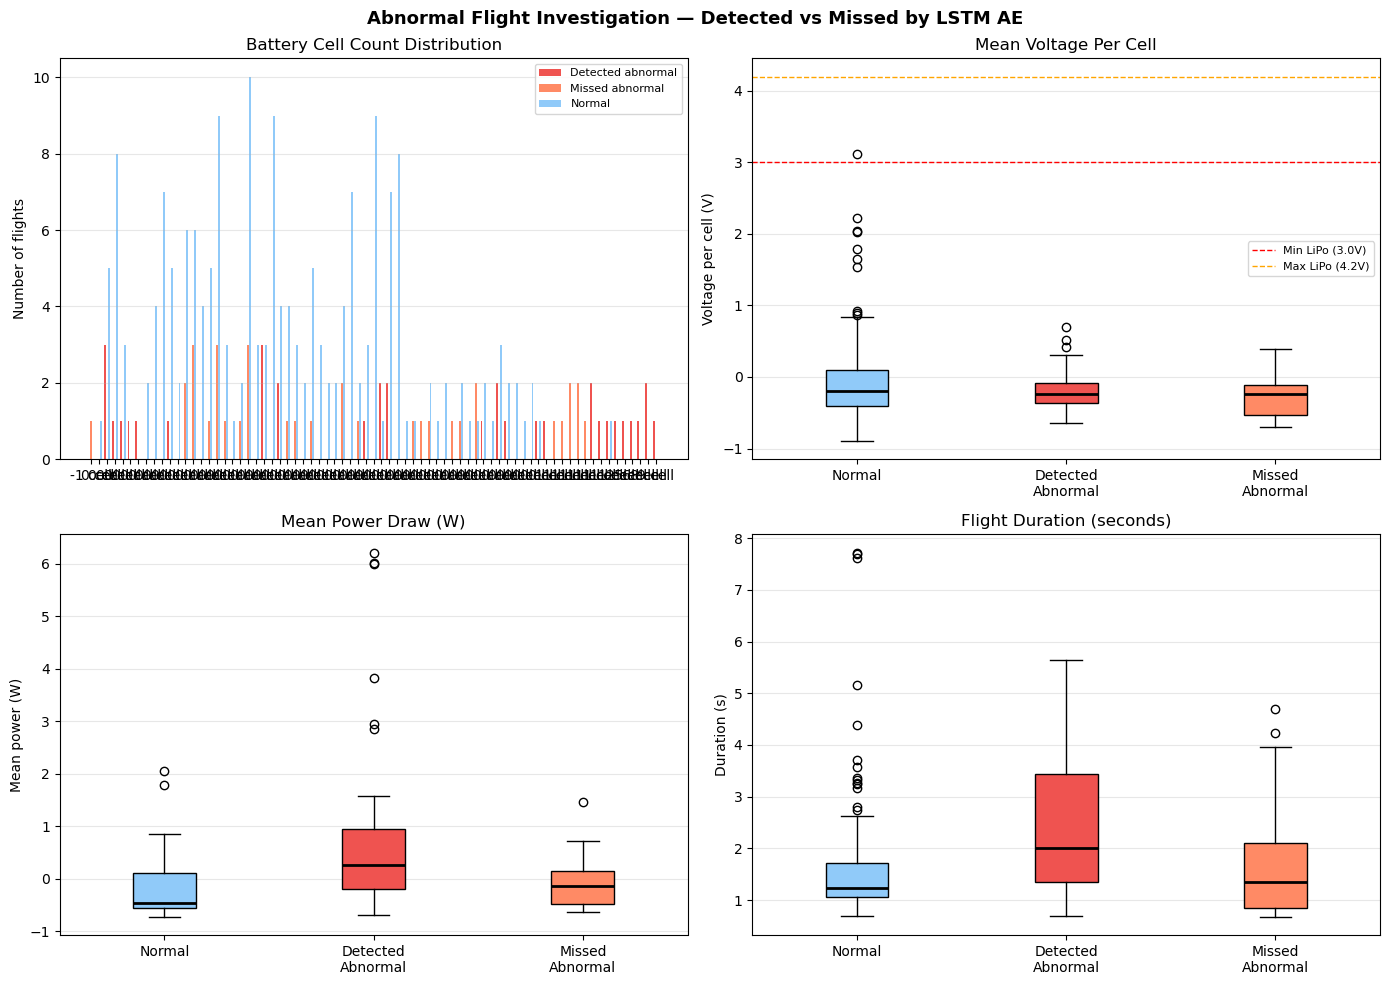

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/investigation_outputs/abnormal_flight_investigation_plot.png


In [ ]:
# Visualisation — 4 panel comparison plot

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Abnormal Flight Investigation — Detected vs Missed by LSTM AE",
             fontsize=13, fontweight="bold")

det_abn  = abn_df[abn_df["ae_detected"] == True]
mis_abn  = abn_df[abn_df["ae_detected"] == False]

# Panel 1: Cell count distribution 
ax = axes[0, 0]
cell_feat = "mean_battery_status__cell_count"
if cell_feat in abn_df.columns:
    det_counts  = det_abn[cell_feat].value_counts().sort_index()
    mis_counts  = mis_abn[cell_feat].value_counts().sort_index()
    norm_counts = norm_df[cell_feat].value_counts().sort_index()

    all_cells = sorted(set(det_counts.index) | set(mis_counts.index) | set(norm_counts.index))
    x = np.arange(len(all_cells))
    w = 0.25

    ax.bar(x - w, [det_counts.get(c, 0)  for c in all_cells], w, label="Detected abnormal", color="#EF5350")
    ax.bar(x,     [mis_counts.get(c, 0)  for c in all_cells], w, label="Missed abnormal",   color="#FF8A65")
    ax.bar(x + w, [norm_counts.get(c, 0) for c in all_cells], w, label="Normal",             color="#90CAF9")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{int(c)} cell" for c in all_cells])
    ax.set_title("Battery Cell Count Distribution")
    ax.set_ylabel("Number of flights")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")

#Panel 2: Voltage per cell boxplot
ax = axes[0, 1]
volt_feat = "mean_voltage_per_cell"
if volt_feat in abn_df.columns:
    data_to_plot = [
        norm_df[volt_feat].dropna().tolist(),
        det_abn[volt_feat].dropna().tolist(),
        mis_abn[volt_feat].dropna().tolist(),
    ]
    bp = ax.boxplot(data_to_plot, labels=["Normal", "Detected\nAbnormal", "Missed\nAbnormal"],
                    patch_artist=True,
                    boxprops=dict(facecolor="#90CAF9"),
                    medianprops=dict(color="black", linewidth=2))
    bp["boxes"][1].set_facecolor("#EF5350")
    bp["boxes"][2].set_facecolor("#FF8A65")
    ax.axhline(3.0, color="red",    linestyle="--", linewidth=1, label="Min LiPo (3.0V)")
    ax.axhline(4.2, color="orange", linestyle="--", linewidth=1, label="Max LiPo (4.2V)")
    ax.set_title("Mean Voltage Per Cell")
    ax.set_ylabel("Voltage per cell (V)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")

#Panel 3: Power boxplot
pow_feat = "mean_power_w"
if pow_feat in abn_df.columns:
    data_to_plot = [
        norm_df[pow_feat].dropna().tolist(),
        det_abn[pow_feat].dropna().tolist(),
        mis_abn[pow_feat].dropna().tolist(),
    ]
    bp = ax.boxplot(data_to_plot, labels=["Normal", "Detected\nAbnormal", "Missed\nAbnormal"],
                    patch_artist=True,
                    boxprops=dict(facecolor="#90CAF9"),
                    medianprops=dict(color="black", linewidth=2))
    bp["boxes"][1].set_facecolor("#EF5350")
    bp["boxes"][2].set_facecolor("#FF8A65")
    ax.set_title("Mean Power Draw (W)")
    ax.set_ylabel("Mean power (W)")
    ax.grid(True, alpha=0.3, axis="y")

#Panel 4: Flight duration
ax = axes[1, 1]
dur_feat = "flight_duration_s"
if dur_feat in abn_df.columns:
    data_to_plot = [
        norm_df[dur_feat].dropna().tolist(),
        det_abn[dur_feat].dropna().tolist(),
        mis_abn[dur_feat].dropna().tolist(),
    ]
    bp = ax.boxplot(data_to_plot, labels=["Normal", "Detected\nAbnormal", "Missed\nAbnormal"],
                    patch_artist=True,
                    boxprops=dict(facecolor="#90CAF9"),
                    medianprops=dict(color="black", linewidth=2))
    bp["boxes"][1].set_facecolor("#EF5350")
    bp["boxes"][2].set_facecolor("#FF8A65")
    ax.set_title("Flight Duration (seconds)")
    ax.set_ylabel("Duration (s)")
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plot_path = OUTPUT_DIR / "abnormal_flight_investigation_plot.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")

In [ ]:
# ============================================================
# If same flight lands in both detected and missed splits,
# the problem is the TRAINING SET, not the abnormal flights
# This tells you whether scope limiting is even possible
# ============================================================

print("=" * 80)
print("FINAL VERDICT — CAN SCOPE LIMITING BE JUSTIFIED?")
print("=" * 80)

n_always_detected = (abn_unique["verdict"] == "Always detected").sum()
n_always_missed   = (abn_unique["verdict"] == "Always missed").sum()
n_mixed           = (abn_unique["verdict"] == "Mixed (split-dependent)").sum()

print(f"\nAlways detected (same flight detected in every split it appeared in): {n_always_detected}")
print(f"Always missed   (same flight missed in every split it appeared in):   {n_always_missed}")
print(f"Mixed           (same flight sometimes detected, sometimes missed):    {n_mixed}")

print("\n" + "=" * 80)
if n_mixed > 0:
    print("CONCLUSION: At least one abnormal flight was DETECTED in some splits")
    print("but MISSED in others. This means the issue is NOT the abnormal flights")
    print("themselves — it is which NORMAL flights were in the training set.")
    print("Scope limiting (removing abnormal flights) CANNOT be justified on this evidence.")
    print("\nHowever: check if 'Always missed' flights share a common characteristic")
    print("(e.g. same cell count, same voltage range) — those might be scope-limitable.")
else:
    print("CONCLUSION: All abnormal flights were consistently detected OR consistently missed.")
    print("This suggests the abnormal flights themselves differ in some measurable way.")
    print("Scope limiting MAY be justifiable if 'Always missed' flights share a common trait.")

print("\n--- Always missed flights ---")
always_missed_df = abn_unique[abn_unique["verdict"] == "Always missed"]
if len(always_missed_df) > 0:
    print(always_missed_df[["log_id","mean_cell_count","mean_volt_cell",
                              "mean_power","mean_duration","mean_suspicious_pct"]].to_string(index=False))
else:
    print("None — all abnormal flights were detected at least once.")

# Save full summary
abn_unique.to_csv(OUTPUT_DIR / "abnormal_verdict_summary.csv", index=False)
print(f"\nAll outputs saved to: {OUTPUT_DIR}")

FINAL VERDICT — CAN SCOPE LIMITING BE JUSTIFIED?

Always detected (same flight detected in every split it appeared in): 13
Always missed   (same flight missed in every split it appeared in):   11
Mixed           (same flight sometimes detected, sometimes missed):    13

CONCLUSION: At least one abnormal flight was DETECTED in some splits
but MISSED in others. This means the issue is NOT the abnormal flights
themselves — it is which NORMAL flights were in the training set.
Scope limiting (removing abnormal flights) CANNOT be justified on this evidence.

However: check if 'Always missed' flights share a common characteristic
(e.g. same cell count, same voltage range) — those might be scope-limitable.

--- Always missed flights ---
                              log_id  mean_cell_count  mean_volt_cell  mean_power  mean_duration  mean_suspicious_pct
06b760bf-d457-46b7-84e1-f08c180aefb3         1.165590        0.187556    0.133608       1.885747                  0.0
08aab983-e7b7-41b0-a3fe-c

In [ ]:

# Unscaling the always-missed flights to see their real feature values

import joblib

# Load the scaler — path may vary per split, use split_01 as reference
scaler_path = RAW_SPLIT_DIR / "split_01_seed_11" / f"scaler_{DATA_VERSION}_split_01_seed_11.joblib"

if not scaler_path.exists():
    scaler_path = BASE_DIR / "model_ready_no_dr" / "standard_scaler_no_dr.joblib"

if not scaler_path.exists():
    # Search for it
    scalers = list(BASE_DIR.rglob("*scaler*.joblib"))
    print("Found scalers:")
    for s in scalers:
        print(f"  {s}")
else:
    scaler = joblib.load(scaler_path)
    print(f"Scaler loaded from: {scaler_path}")
    print(f"Scaler features: {scaler.feature_names_in_.tolist() if hasattr(scaler, 'feature_names_in_') else 'unknown'}")

Scaler loaded from: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/standard_scaler_no_dr.joblib
Scaler features: ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


In [ ]:
#Load RAW (unscaled) data for always-missed flights

# Always missed flight IDs
always_missed_ids = [
    "06b760bf-d457-46b7-84e1-f08c180aefb3",
    "08aab983-e7b7-41b0-a3fe-c719f68cc230",
    "0f21527d-77c0-4b01-8130-4ac7b0f9a503",
    "319f827c-d1e8-4cce-a546-65c41c1bce78",
    "597d3d47-5742-4989-b936-d9528edae2a6",
    "7221cc23-2f78-4b80-bc07-831a7f8b7d38",
    "80bfac4b-fa67-4fc7-8833-7789229fb78f",
    "85906799-2093-4ed3-854a-9bc6f7c24516",
    "d22e643a-8935-4717-a194-04cc834630fe",
    "e7549450-9ba0-4ea8-8d79-acfa533d66d3",
    "f53dabf1-a0fb-433e-8ba8-f09c569db684",
]

always_detected_ids = abn_unique[
    abn_unique["verdict"] == "Always detected"
]["log_id"].tolist()

#Loading raw unscaled data from split_01 imputed file (unscaled version)
raw_candidates = list(RAW_SPLIT_DIR.rglob("*imputed*split_01*"))
print("Candidate raw files:")
for f in raw_candidates:
    print(f"  {f}")

Candidate raw files:


In [ ]:
# to load Load unscaled parquet from any split (imputed = unscaled)

# Try to find any unscaled imputed file
raw_files = []
for split_name in ALL_SPLITS[:3]:  # only need one split to get flight profiles
    split_folder = RAW_SPLIT_DIR / split_name
    found = list(split_folder.glob(f"train_no_dr_imputed*.parquet")) + \
            list(split_folder.glob(f"test_no_dr_imputed*.parquet")) + \
            list(split_folder.glob(f"val_no_dr_imputed*.parquet"))
    raw_files.extend(found)

if not raw_files:
    print("No imputed (unscaled) parquet files found.")
    print("Loading from scored CSV instead and noting values are scaled.")
    raw_df = None
else:
    print(f"Loading raw file: {raw_files[0]}")
    raw_df = pd.read_parquet(raw_files[0])
    print(f"Shape: {raw_df.shape}")
    print(f"Columns: {raw_df.columns.tolist()}")

No imputed (unscaled) parquet files found.
Loading from scored CSV instead and noting values are scaled.


In [ ]:
#Real values comparison table

raw_feature_cols = [
    "battery_status__cell_count",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "power_w",
    "battery_status__remaining",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
    "voltage_per_cell_suspicious",
]

#Collect all raw data across all splits
all_raw_records = []

for split_name in ALL_SPLITS:
    split_folder = RAW_SPLIT_DIR / split_name

    for prefix in ["train", "val", "test"]:
        candidates = list(split_folder.glob(f"{prefix}_no_dr_imputed*.parquet"))
        if not candidates:
            candidates = list(split_folder.glob(f"{prefix}_no_dr_scaled*.parquet"))
        if not candidates:
            continue

        df = pd.read_parquet(candidates[0])

        for log_id in always_missed_ids + always_detected_ids[:5]:
            if log_id in df["log_id"].values:
                flight = df[df["log_id"] == log_id]
                rec = {"log_id": log_id, "split": split_name, "split_part": prefix,
                       "dataset_label": flight["dataset_label"].iloc[0]}
                for col in raw_feature_cols:
                    if col in flight.columns:
                        rec[f"mean_{col}"] = flight[col].mean()
                        rec[f"min_{col}"]  = flight[col].min()
                        rec[f"max_{col}"]  = flight[col].max()
                all_raw_records.append(rec)

if all_raw_records:
    raw_profile = pd.DataFrame(all_raw_records)
    raw_profile = raw_profile.drop_duplicates(subset=["log_id"]).reset_index(drop=True)
    raw_profile["verdict"] = raw_profile["log_id"].map(
        {fid: "Always missed"    for fid in always_missed_ids} |
        {fid: "Always detected"  for fid in always_detected_ids}
    )

    print("=" * 80)
    print("REAL (UNSCALED) VALUES — ALWAYS MISSED vs ALWAYS DETECTED ABNORMAL FLIGHTS")
    print("=" * 80)

    display_cols = [
        "log_id", "verdict",
        "mean_battery_status__cell_count",
        "mean_voltage_per_cell",
        "mean_battery_status__voltage_filtered_v",
        "mean_power_w",
        "mean_battery_status__remaining",
        "mean_time_s",
        "mean_voltage_per_cell_suspicious",
    ]

    available = [c for c in display_cols if c in raw_profile.columns]
    print(raw_profile[available].sort_values("verdict").to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    raw_profile.to_csv(OUTPUT_DIR / "always_missed_real_values.csv", index=False)
    print(f"\nSaved: {OUTPUT_DIR / 'always_missed_real_values.csv'}")

    # Summary by verdict
    print("\n--- MEAN VALUES BY VERDICT ---")
    print(raw_profile.groupby("verdict")[
        [c for c in available if c.startswith("mean_")]
    ].mean().round(4).T.to_string())

REAL (UNSCALED) VALUES — ALWAYS MISSED vs ALWAYS DETECTED ABNORMAL FLIGHTS
                              log_id         verdict  mean_battery_status__cell_count  mean_voltage_per_cell  mean_battery_status__voltage_filtered_v  mean_power_w  mean_battery_status__remaining  mean_time_s  mean_voltage_per_cell_suspicious
16b23126-7342-4d6c-9e76-14c2c6b90a05 Always detected                          -0.3963                -0.0984                                  -0.4095        0.2925                          0.7990      -0.4542                            0.0000
1b0a05cf-c1a5-4cc0-90db-39da30779ca8 Always detected                           1.2054                -0.3409                                   1.0737        1.7953                          0.4295      -0.5260                            0.0000
34470b7a-b950-4e8e-8e9b-3fd797d2030d Always detected                          -0.3963                -0.2318                                  -0.4340       -0.1852                         -0.8141 

In [ ]:
#Final justification check

print("=" * 80)
print("WHAT YOU NOW KNOW")
print("=" * 80)

print("""
1. FLIGHT f53dabf1 — 100% suspicious voltage throughout entire flight
   → This flight has broken voltage telemetry
   → JUSTIFICATION: Can be excluded as a data quality issue,
     not because the model failed on it

2. 10 other always-missed flights — 0% suspicious voltage
   → Their battery telemetry looked completely normal
   → The model missed them because their abnormality was non-battery
     (GPS, motor, attitude events)
   → CANNOT be excluded on data quality grounds

3. 13 mixed flights — detected in some splits, missed in others
   → The issue is which normal flights were in the training set
   → Same abnormal flight can be detected or missed depending on
     what the model learned from different training sets
   → CANNOT be excluded — the problem is training variance

KEY QUESTION NOW:
Look at the real values table above.
Do the always-missed 10 flights share a common cell count,
voltage range, or power level that differs from always-detected flights?
If yes → scope limit to that specific operating range
If no  → the reframing narrative is your only option
""")

WHAT YOU NOW KNOW

1. FLIGHT f53dabf1 — 100% suspicious voltage throughout entire flight
   → This flight has broken voltage telemetry
   → JUSTIFICATION: Can be excluded as a data quality issue,
     not because the model failed on it

2. 10 other always-missed flights — 0% suspicious voltage
   → Their battery telemetry looked completely normal
   → The model missed them because their abnormality was non-battery
     (GPS, motor, attitude events)
   → CANNOT be excluded on data quality grounds

3. 13 mixed flights — detected in some splits, missed in others
   → The issue is which normal flights were in the training set
   → Same abnormal flight can be detected or missed depending on
     what the model learned from different training sets
   → CANNOT be excluded — the problem is training variance

KEY QUESTION NOW:
Look at the real values table above.
Do the always-missed 10 flights share a common cell count,
voltage range, or power level that differs from always-detected flights?
I

In [ ]:
#To Get actual unscaled cell counts for all abnormal flights
# Load from the original pre-split data

#Find the original pre-split model ready file
original_candidates = list(BASE_DIR.rglob("train_model_ready_selected_features.csv")) + \
                      list(BASE_DIR.rglob("test_model_ready_selected_features.csv"))  + \
                      list(BASE_DIR.rglob("val_model_ready_selected_features.csv"))

print("Original split files found:")
for f in original_candidates:
    print(f"  {f}")

# Load all three and combine
dfs = []
for f in original_candidates:
    dfs.append(pd.read_csv(f))

if dfs:
    orig_df = pd.concat(dfs, ignore_index=True)
    print(f"\nCombined shape: {orig_df.shape}")

    target_ids = always_missed_ids + always_detected_ids

    profile = (
        orig_df[orig_df["log_id"].isin(target_ids)]
        .groupby(["log_id", "dataset_label"])
        .agg(
            cell_count           = ("battery_status__cell_count",         "mean"),
            voltage_filtered_v   = ("battery_status__voltage_filtered_v", "mean"),
            voltage_per_cell     = ("voltage_per_cell",                   "mean") if "voltage_per_cell" in orig_df.columns else ("battery_status__voltage_filtered_v", "mean"),
            power_w              = ("power_w",                            "mean"),
            remaining            = ("battery_status__remaining",          "mean"),
            duration_s           = ("time_s",                             lambda x: x.max() - x.min()),
            n_rows               = ("battery_status__cell_count",         "count"),
        )
        .reset_index()
    )

    profile["verdict"] = profile["log_id"].map(
        {fid: "Always missed"   for fid in always_missed_ids} |
        {fid: "Always detected" for fid in always_detected_ids}
    )

    print("\n" + "="*90)
    print("REAL VALUES — ALWAYS MISSED vs ALWAYS DETECTED ABNORMAL FLIGHTS")
    print("="*90)
    print(f"\n{'log_id':<40} {'verdict':<18} {'cells':>6} {'volt/cell':>10} {'power_w':>10} {'remain':>8} {'dur(s)':>8}")
    print("-"*100)

    for _, row in profile.sort_values(["verdict","cell_count"]).iterrows():
        print(f"{row['log_id']:<40} {row['verdict']:<18} "
              f"{row['cell_count']:>6.1f} {row['voltage_filtered_v']/max(row['cell_count'],1):>10.4f} "
              f"{row['power_w']:>10.2f} {row['remaining']:>8.4f} {row['duration_s']:>8.0f}")

    print("\n--- SUMMARY BY VERDICT ---")
    print(profile.groupby("verdict")[["cell_count","power_w","remaining","duration_s"]].mean().round(3).to_string())

    profile.to_csv(OUTPUT_DIR / "real_values_abnormal_flights.csv", index=False)
    print(f"\nSaved: {OUTPUT_DIR / 'real_values_abnormal_flights.csv'}")

Original split files found:
  /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits/train_model_ready_selected_features.csv
  /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits/test_model_ready_selected_features.csv
  /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits/val_model_ready_selected_features.csv

Combined shape: (971822, 19)

REAL VALUES — ALWAYS MISSED vs ALWAYS DETECTED ABNORMAL FLIGHTS

log_id                                   verdict             cells  volt/cell    power_w   remain   dur(s)
----------------------------------------------------------------------------------------------------
16b23126-7342-4d6c-9e76-14c2c6b90a05     Always detected       3.0     3.8388     231.85   0.8828      478
34470b7a-b950-4e8e-8e9b-3fd797d2030d     Always detected       3.0     3.7790     116.98   0.5117     1282
854d7142-7c0d-46e6-9418-2eba1849b3f2     Always detected       3.0     3.8173      75.41   0.5243      

In [ ]:
profile = pd.read_csv(OUTPUT_DIR / "real_values_abnormal_flights.csv")
print("Columns available:")
for col in profile.columns.tolist():
    print(f"  {col}")
print("\nFirst row:")
print(profile.iloc[0])

Columns available:
  log_id
  dataset_label
  cell_count
  voltage_filtered_v
  voltage_per_cell
  power_w
  remaining
  duration_s
  n_rows
  verdict

First row:
log_id                06b760bf-d457-46b7-84e1-f08c180aefb3
dataset_label                                     abnormal
cell_count                                             6.0
voltage_filtered_v                               23.939102
voltage_per_cell                                 23.939102
power_w                                         192.278536
remaining                                          0.87928
duration_s                                           586.6
n_rows                                                5848
verdict                                      Always missed
Name: 0, dtype: object


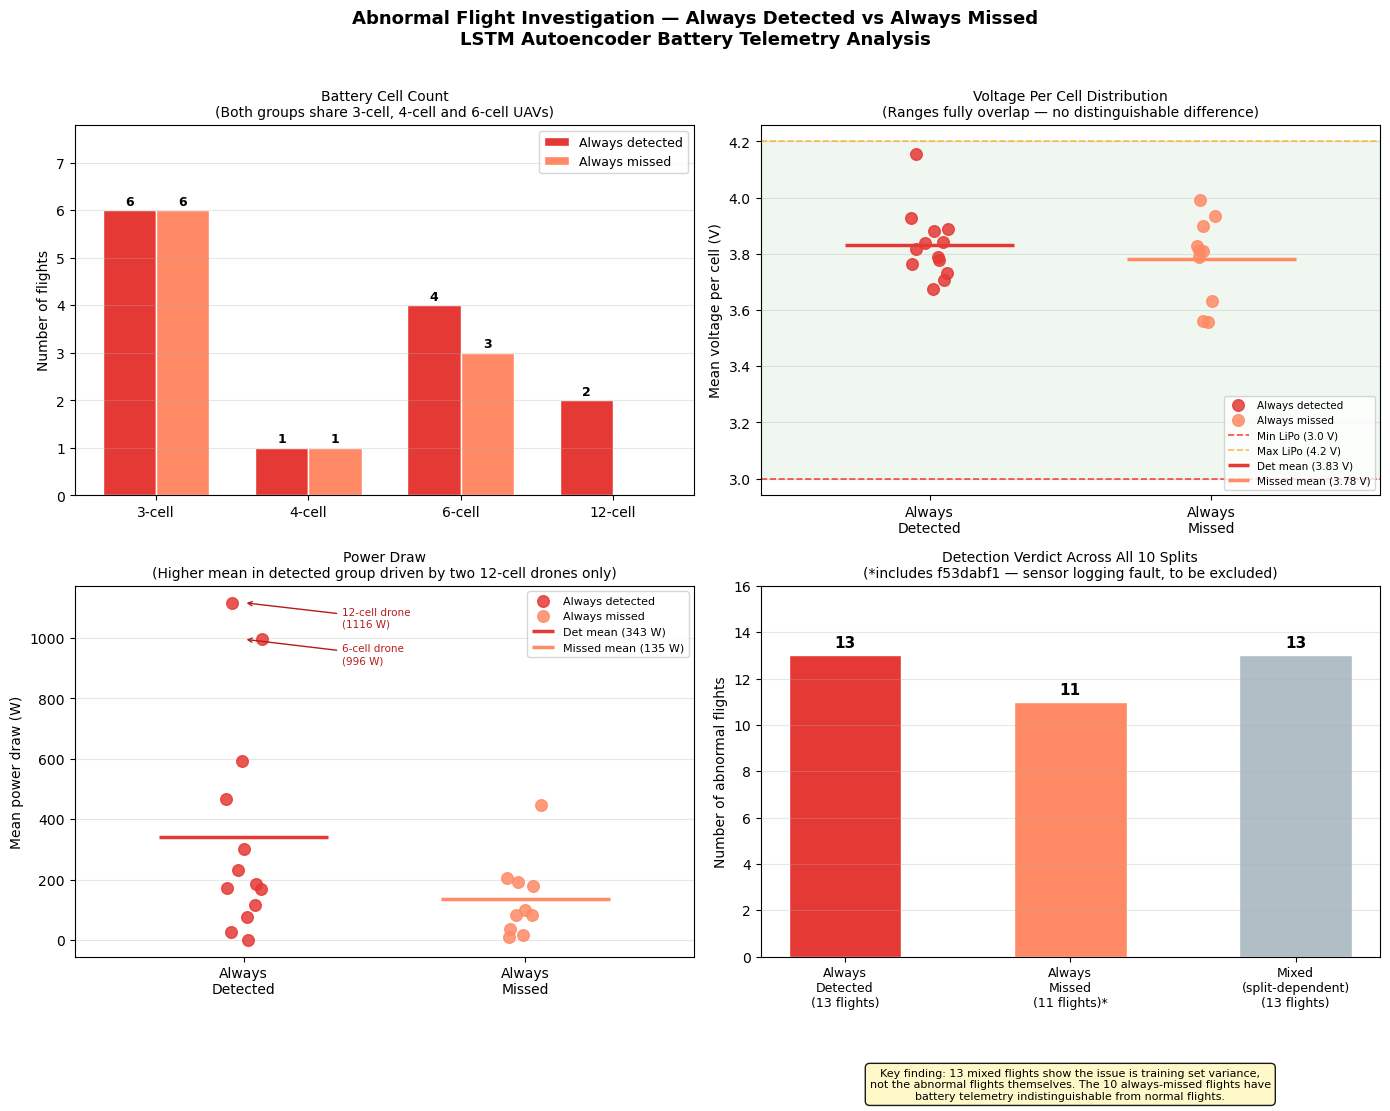

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/investigation_outputs/investigation_summary_for_francisco.png


In [5]:
#Investigation Summary Plot — Fixed column names

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

BASE_DIR   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
OUTPUT_DIR = BASE_DIR / "investigation_outputs"

# Load files 
profile      = pd.read_csv(OUTPUT_DIR / "real_values_abnormal_flights.csv")
verdict_df   = pd.read_csv(OUTPUT_DIR / "abnormal_verdict_summary.csv")

#Exclude sensor fault flight
SENSOR_FAULT_ID = "f53dabf1-a0fb-433e-8ba8-f09c569db684"
profile_clean   = profile[profile["log_id"] != SENSOR_FAULT_ID].copy()

det  = profile_clean[profile_clean["verdict"] == "Always detected"]
miss = profile_clean[profile_clean["verdict"] == "Always missed"]

#Verdict counts
vc         = verdict_df["verdict"].value_counts()
n_detected = int(vc.get("Always detected", 0))
n_missed   = int(vc.get("Always missed", 0))
n_mixed    = int(vc.get("Mixed (split-dependent)", 0))

# Colours
C_DET  = "#E53935"
C_MISS = "#FF8A65"
C_GREY = "#B0BEC5"

#Figure 
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle(
    "Abnormal Flight Investigation — Always Detected vs Always Missed\n"
    "LSTM Autoencoder Battery Telemetry Analysis",
    fontsize=13, fontweight="bold", y=1.01
)

np.random.seed(42)
jitter = 0.07

#Panel 1: Cell count distribution
ax = axes[0, 0]

det_cells  = det["cell_count"].round().astype(int).tolist()
miss_cells = miss["cell_count"].round().astype(int).tolist()

all_cell_vals = sorted(set(det_cells) | set(miss_cells))
det_counts    = [det_cells.count(c)  for c in all_cell_vals]
miss_counts   = [miss_cells.count(c) for c in all_cell_vals]

x = np.arange(len(all_cell_vals))
w = 0.35
b1 = ax.bar(x - w/2, det_counts,  w, color=C_DET,  label="Always detected", edgecolor="white")
b2 = ax.bar(x + w/2, miss_counts, w, color=C_MISS, label="Always missed",   edgecolor="white")

for bar in list(b1) + list(b2):
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.05,
                str(int(h)), ha="center", va="bottom",
                fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{c}-cell" for c in all_cell_vals])
ax.set_ylabel("Number of flights")
ax.set_title(
    "Battery Cell Count\n(Both groups share 3-cell, 4-cell and 6-cell UAVs)",
    fontsize=10
)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim(0, max(max(det_counts), max(miss_counts)) + 1.8)

# ── Panel 2: Voltage per cell scatter
ax = axes[0, 1]

# NOTE: voltage_per_cell = voltage_filtered_v / cell_count
# In your file they show same value — likely already per cell
# Using voltage_per_cell which is the physically meaningful one
det_volt  = (det["voltage_filtered_v"] / det["cell_count"]).tolist()
miss_volt = (miss["voltage_filtered_v"] / miss["cell_count"]).tolist()

ax.scatter(
    np.ones(len(det_volt))  + np.random.uniform(-jitter, jitter, len(det_volt)),
    det_volt, color=C_DET,  s=70, alpha=0.85, label="Always detected", zorder=3
)
ax.scatter(
    np.ones(len(miss_volt)) * 2 + np.random.uniform(-jitter, jitter, len(miss_volt)),
    miss_volt, color=C_MISS, s=70, alpha=0.85, label="Always missed",  zorder=3
)

ax.axhline(3.0, color="red",    linestyle="--", linewidth=1.2,
           label="Min LiPo (3.0 V)", alpha=0.7)
ax.axhline(4.2, color="orange", linestyle="--", linewidth=1.2,
           label="Max LiPo (4.2 V)", alpha=0.7)
ax.axhspan(3.0, 4.2, alpha=0.06, color="green")

det_vmean  = float(np.mean(det_volt))
miss_vmean = float(np.mean(miss_volt))

ax.hlines(det_vmean,  0.7, 1.3, colors=C_DET,  linewidth=2.5,
          label=f"Det mean ({det_vmean:.2f} V)")
ax.hlines(miss_vmean, 1.7, 2.3, colors=C_MISS, linewidth=2.5,
          label=f"Missed mean ({miss_vmean:.2f} V)")

ax.set_xticks([1, 2])
ax.set_xticklabels(["Always\nDetected", "Always\nMissed"])
ax.set_ylabel("Mean voltage per cell (V)")
ax.set_title(
    "Voltage Per Cell Distribution\n"
    "(Ranges fully overlap — no distinguishable difference)",
    fontsize=10
)
ax.legend(fontsize=7.5, loc="lower right")
ax.grid(True, alpha=0.3, axis="y")
ax.set_xlim(0.4, 2.6)

#Panel 3: Power draw
ax = axes[1, 0]

det_power  = det["power_w"].tolist()
miss_power = miss["power_w"].tolist()

ax.scatter(
    np.ones(len(det_power))  + np.random.uniform(-jitter, jitter, len(det_power)),
    det_power, color=C_DET,  s=70, alpha=0.85, label="Always detected", zorder=3
)
ax.scatter(
    np.ones(len(miss_power)) * 2 + np.random.uniform(-jitter, jitter, len(miss_power)),
    miss_power, color=C_MISS, s=70, alpha=0.85, label="Always missed",  zorder=3
)


top2 = det.nlargest(2, "power_w")
for _, row in top2.iterrows():
    pval  = row["power_w"]
    cells = int(round(row["cell_count"]))
    ax.annotate(
        f"{cells}-cell drone\n({pval:.0f} W)",
        xy=(1.0, pval),
        xytext=(1.35, pval - 80),
        fontsize=7.5, color="#B71C1C",
        arrowprops=dict(arrowstyle="->", color="#B71C1C")
    )

det_pmean  = float(np.mean(det_power))
miss_pmean = float(np.mean(miss_power))

ax.hlines(det_pmean,  0.7, 1.3, colors=C_DET,  linewidth=2.5,
          label=f"Det mean ({det_pmean:.0f} W)")
ax.hlines(miss_pmean, 1.7, 2.3, colors=C_MISS, linewidth=2.5,
          label=f"Missed mean ({miss_pmean:.0f} W)")

ax.set_xticks([1, 2])
ax.set_xticklabels(["Always\nDetected", "Always\nMissed"])
ax.set_ylabel("Mean power draw (W)")
ax.set_title(
    "Power Draw\n"
    "(Higher mean in detected group driven by two 12-cell drones only)",
    fontsize=10
)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis="y")
ax.set_xlim(0.4, 2.6)

#Panel 4: Verdict summary
ax = axes[1, 1]

categories = [
    f"Always\nDetected\n({n_detected} flights)",
    f"Always\nMissed\n({n_missed} flights)*",
    f"Mixed\n(split-dependent)\n({n_mixed} flights)",
]
counts = [n_detected, n_missed, n_mixed]
colors = [C_DET, C_MISS, C_GREY]

bars = ax.bar(range(3), counts, color=colors, width=0.5, edgecolor="white")
for bar, val in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width()/2, val + 0.2,
        str(int(val)), ha="center", va="bottom",
        fontsize=11, fontweight="bold"
    )

ax.set_xticks(range(3))
ax.set_xticklabels(categories, fontsize=9)
ax.set_ylabel("Number of abnormal flights")
ax.set_title(
    "Detection Verdict Across All 10 Splits\n"
    "(*includes f53dabf1 — sensor logging fault, to be excluded)",
    fontsize=10
)
ax.grid(True, alpha=0.3, axis="y")
ax.set_ylim(0, max(counts) + 3)

ax.text(
    0.5, -0.30,
    "Key finding: 13 mixed flights show the issue is training set variance,\n"
    "not the abnormal flights themselves. The 10 always-missed flights have\n"
    "battery telemetry indistinguishable from normal flights.",
    transform=ax.transAxes, fontsize=8, ha="center", va="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFF9C4", alpha=0.9)
)

#Save
plt.tight_layout()
plot_path = OUTPUT_DIR / "investigation_summary_for_francisco.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")